# Chapter 19 · Rough volatility: interactive demos

Companion to Chapter 19 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/19-rough-volatility.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

**Data.** Section 2 tries to download the daily 5-minute realized variance of the S&P 500 (column `SPX2.rv`,
January 2000 to November 2013) from the Oxford-Man Institute's realized library (Heber, Lunde, Shephard and
Sheppard, 2009). The data are the Oxford-Man Institute's and subject to its terms of use; the notebook reads the copy
distributed with the R package [midasr](https://github.com/mpiktas/midasr) (file `data/rvsp500.RData` at tag v0.9,
checked against a pinned SHA-256) with a small parser in `ieor222.roughvol`, and nothing is stored in this repository.
Offline, or when the environment variable `IEOR222_OFFLINE=1` is set, it falls back on a simulated series: the copy of
this notebook in the repository was run that way, so run it yourself to see the S&P 500. To use your own data,
replace `rv` in Section 2 by any array of daily realized variances.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown

from ieor222.roughvol import (daily_proxies, fbm_cholesky, fgn_autocov, gjr_estimate, hybrid_J, hybrid_mse,
                              load_spx_realized_variance, mvn_constant, powerlaw_fit, rbergomi_first_order_skew,
                              rbergomi_smiles, rfsv_logvol, rough_heston_smile)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. Fractional Brownian motion

A fBM $W^H$ is the centred Gaussian process with covariance $\frac12(s^{2H}+t^{2H}-|t-s|^{2H})$. Below, exact paths
(Cholesky factorization of the covariance on the grid) for several $H$ from the **same** normal draws, and the
correlation $\rho_H(n)$ of increments $n$ steps apart: negative for $H<\frac12$, positive for $H>\frac12$.

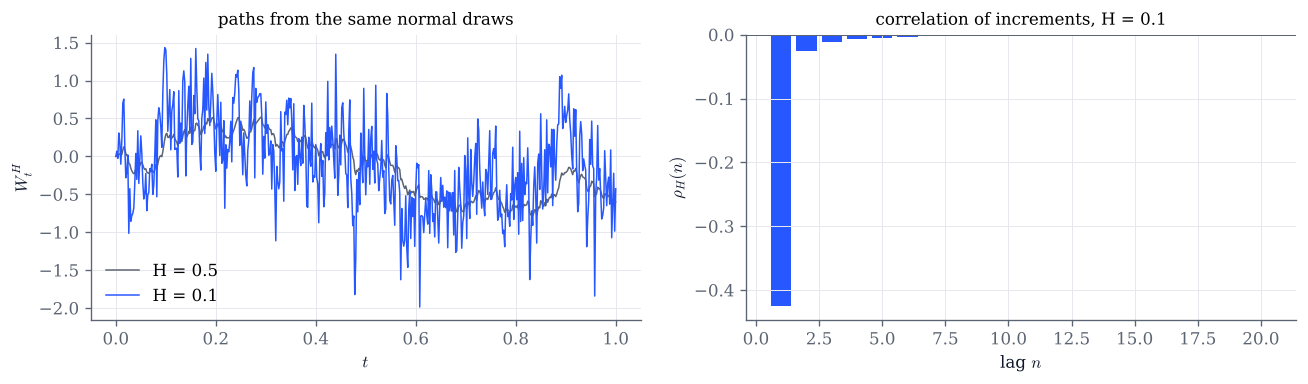

In [2]:
def fbm_demo(H=0.1, seed=0):
    n = 500
    G = np.random.default_rng(seed).standard_normal((1, n))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.3))
    for h, color in ((0.5, GREY), (H, COBALT)):
        t, X = fbm_cholesky(h, 1.0, n, normals=G)
        ax.plot(t, X[0], color=color, lw=0.9, label=f"H = {h:g}")
    ax.set(xlabel="$t$", ylabel="$W^H_t$", title="paths from the same normal draws")
    ax.legend()
    lags = np.arange(1, 21)
    ax2.bar(lags, fgn_autocov(lags, H), color=COBALT)
    ax2.axhline(0, color=GREY, lw=0.6)
    ax2.set(xlabel="lag $n$", ylabel=r"$\rho_H(n)$", title=f"correlation of increments, H = {H:g}")
    fig.tight_layout(); plt.show()

fbm_demo()

In [3]:
# Explore: move H across 1/2 and watch the paths and the sign of the correlations change.
interact(fbm_demo,
         H=FloatSlider(value=0.1, min=0.02, max=0.98, step=0.02, continuous_update=False, description="H"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. Volatility is rough: the GJR regression

Gatheral, Jaisson and Rosenbaum compute, from daily log-volatilities $x_k=\frac12\log(\text{realized variance})$,
$$m(q,\Delta)=\frac1N\sum_j|x_{j\Delta}-x_{(j-1)\Delta}|^q$$
(averaged over starting points), regress $\log m(q,\Delta)$ on $\log\Delta$ for $\Delta=1,\dots,30$ days, and find
slopes $\zeta_q=qH$ with $H\approx0.1$–$0.15$. For fBM this scaling is exact (moment-scaling proposition of the notes).

The next cell downloads the S&P 500 realized variance if it can, and otherwise uses a simulated RFSV series.

simulated RFSV series (offline fallback), H = 0.14
zeta_q / q: [0.136  0.137  0.1377 0.1383 0.1398]   H estimate: 0.1389   nu estimate: 0.301


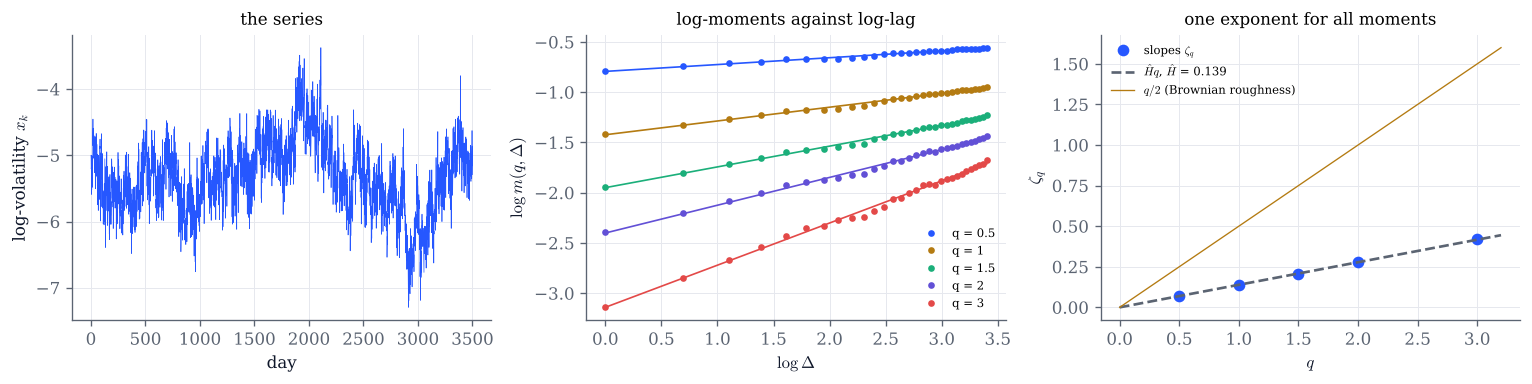

In [4]:
data = load_spx_realized_variance()
if data is not None:
    dates, rv = data
    source = f"S&P 500 realized variance, {dates[0]} to {dates[-1]}, {rv.size} days"
else:
    t_sim, X_sim = rfsv_logvol(H=0.14, nu=0.3, lam=5e-4, n_days=3500, steps_per_day=1, seed=1)
    rv = np.exp(2 * X_sim[:-1])
    source = "simulated RFSV series (offline fallback), H = 0.14"
x = 0.5 * np.log(rv)
est = gjr_estimate(x)
print(source)
print("zeta_q / q:", np.round(est["zeta"] / est["qs"], 4), "  H estimate:", round(est["H"], 4),
      "  nu estimate:", round(float(np.sqrt(np.exp(est["intercept"][3]))), 3))

fig, (ax0, ax, ax2) = plt.subplots(1, 3, figsize=(13, 3.3))
ax0.plot(x, color=COBALT, lw=0.4)
ax0.set(xlabel="day", ylabel="log-volatility $x_k$", title="the series")
L = np.log(est["lags"])
for i, (q, color) in enumerate(zip(est["qs"], PALETTE)):
    ax.plot(L, est["logm"][i], "o", ms=3, color=color, label=f"q = {q:g}")
    ax.plot(L, est["intercept"][i] + est["zeta"][i] * L, color=color, lw=1)
ax.set(xlabel=r"$\log\Delta$", ylabel=r"$\log m(q,\Delta)$", title="log-moments against log-lag"); ax.legend(fontsize=7)
ax2.plot(est["qs"], est["zeta"], "o", color=COBALT, label="slopes $\\zeta_q$")
ax2.plot([0, 3.2], [0, 3.2 * est["H"]], color=GREY, ls="--", label=f"$\\hat H q$, $\\hat H$ = {est['H']:.3f}")
ax2.plot([0, 3.2], [0, 1.6], color=GOLD, lw=0.8, label="$q/2$ (Brownian roughness)")
ax2.set(xlabel="$q$", ylabel=r"$\zeta_q$", title="one exponent for all moments"); ax2.legend(fontsize=7)
fig.tight_layout(); plt.show()

**Explore** the regression on simulated RFSV log-volatility $X=m+\nu(W^H-\lambda\int_0^\cdot e^{-\lambda(\cdot-s)}W^H_s\,ds)$, sampled
daily as spot values or as the log of $\sigma^2$ averaged over part of each day (a realized-variance proxy, here the
average over the 8 or 64 grid points of the first hour or eight hours, with 192 steps per day). Averaging
biases $\hat H$ upwards; strong mean reversion bends the log-moment lines and biases it downwards.

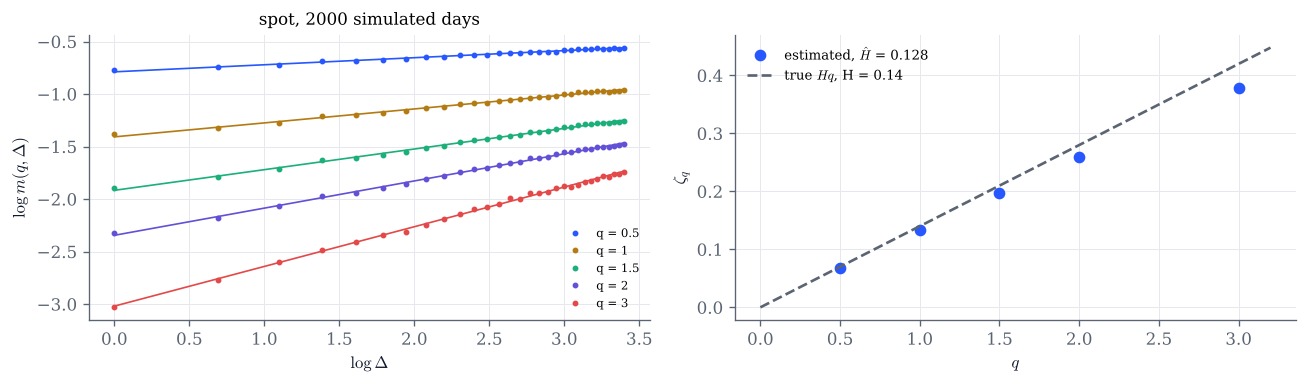

In [5]:
def gjr_demo(H=0.14, nu=0.3, lam=5e-4, proxy="spot", max_lag=30, seed=5):
    spd = 192
    t, X = rfsv_logvol(H=H, nu=nu, lam=lam, n_days=2000, steps_per_day=spd, seed=seed)
    spot, p8 = daily_proxies(t, X, spd, window=1 / 3)
    _, p1 = daily_proxies(t, X, spd, window=1 / 24)
    series = {"spot": spot, "1-hour average": p1, "8-hour average": p8}[proxy]
    e = gjr_estimate(series, lags=range(1, max_lag + 1))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.3))
    L = np.log(e["lags"])
    for i, (q, color) in enumerate(zip(e["qs"], PALETTE)):
        ax.plot(L, e["logm"][i], "o", ms=2.5, color=color, label=f"q = {q:g}")
        ax.plot(L, e["intercept"][i] + e["zeta"][i] * L, color=color, lw=1)
    ax.set(xlabel=r"$\log\Delta$", ylabel=r"$\log m(q,\Delta)$", title=f"{proxy}, 2000 simulated days"); ax.legend(fontsize=7)
    ax2.plot(e["qs"], e["zeta"], "o", color=COBALT, label=f"estimated, $\\hat H$ = {e['H']:.3f}")
    ax2.plot([0, 3.2], [0, 3.2 * H], color=GREY, ls="--", label=f"true $H q$, H = {H:g}")
    ax2.set(xlabel="$q$", ylabel=r"$\zeta_q$"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()

gjr_demo()

In [6]:
interact(gjr_demo,
         H=FloatSlider(value=0.14, min=0.05, max=0.45, step=0.01, continuous_update=False, description="H"),
         nu=FloatSlider(value=0.3, min=0.05, max=1.0, step=0.05, continuous_update=False, description="ν"),
         lam=FloatLogSlider(value=5e-4, base=10, min=-5, max=-0.5, step=0.25, continuous_update=False, description="λ (/day)"),
         proxy=Dropdown(options=["spot", "1-hour average", "8-hour average"], value="spot", description="proxy"),
         max_lag=IntSlider(value=30, min=5, max=250, step=5, continuous_update=False, description="max lag"),
         seed=IntSlider(value=5, min=0, max=50, continuous_update=False, description="seed"));

## 3. The Riemann–Liouville process against fBM

$Y_t=\sqrt{2H}\int_0^t(t-u)^{H-1/2}dW_u$ has $\mathrm{Var}\,Y_t=t^{2H}$ but non-stationary increments:
$\mathbb E(Y_{s+h}-Y_s)^2/h^{2H}$ grows from $1$ at $s=0$ to $2Hc_H^2$ as $s/h\to\infty$, where $c_H^2$ is the
Mandelbrot–Van Ness constant. Locally it is as rough as fBM.

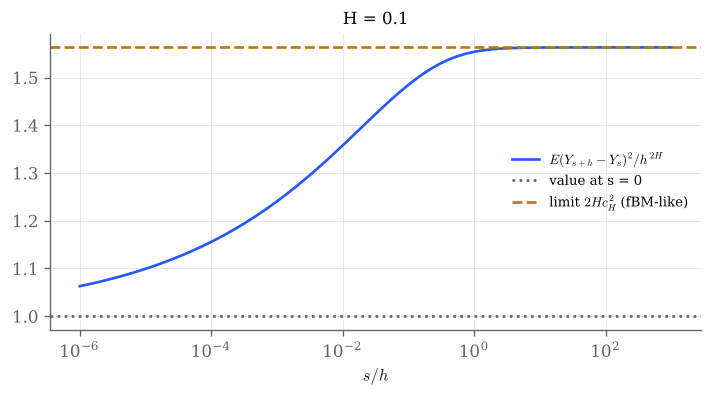

In [7]:
from scipy.integrate import quad

def rl_demo(H=0.1):
    a = H - 0.5
    r = np.geomspace(1e-6, 1e3, 70)
    inner = [quad(lambda x: ((1 + x) ** a - x ** a) ** 2, 0, rr, limit=200)[0] for rr in r]
    ratio = 1 + 2 * H * np.array(inner)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.semilogx(r, ratio, color=COBALT, label=r"$E(Y_{s+h}-Y_s)^2/h^{2H}$")
    ax.axhline(1, color=GREY, ls=":", label="value at s = 0")
    ax.axhline(2 * H * mvn_constant(H), color=GOLD, ls="--", label=r"limit $2Hc_H^2$ (fBM-like)")
    ax.set(xlabel="$s/h$", title=f"H = {H:g}"); ax.legend(fontsize=8)
    plt.show()

rl_demo()

In [8]:
interact(rl_demo, H=FloatSlider(value=0.1, min=0.02, max=0.95, step=0.01, continuous_update=False, description="H"));

## 4. Simulation: the hybrid scheme

The hybrid scheme approximates $Y$ on the grid $t_i=i/n$ by integrating the singular kernel exactly on the last $\ell$
cells and freezing it at $b_k/n$ on the others. Its mean-square error is exact,
$2Hn^{-2H}\sum_{k>\ell}\int_{k-1}^k(y^\alpha-b_k^\alpha)^2dy$ with $\alpha=H-\frac12$, and decays like $n^{-H}$ in
root-mean-square — slowly — but with a constant that drops by two orders of magnitude when $\ell=1$ and the optimal
points $b_k^*$ are used. (At $H=\frac12$ the kernel is constant and the scheme is exact.)

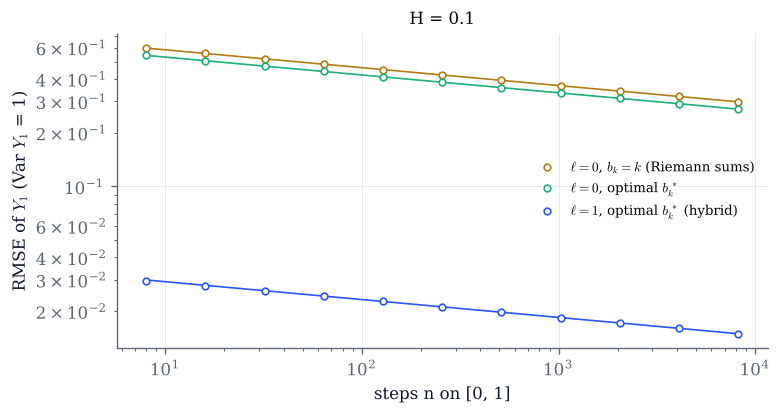

In [9]:
def hybrid_demo(H=0.1):
    ns = 2 ** np.arange(3, 14)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for (ell, pts), color, lab in (((0, "left"), GOLD, r"$\ell=0$, $b_k = k$ (Riemann sums)"),
                                   ((0, "optimal"), GREEN, r"$\ell=0$, optimal $b_k^*$"),
                                   ((1, "optimal"), COBALT, r"$\ell=1$, optimal $b_k^*$ (hybrid)")):
        rmse = np.sqrt([hybrid_mse(H, n, n, ell, pts) for n in ns])
        ax.loglog(ns, np.sqrt(2 * H * hybrid_J(H, ell, pts)) * ns ** (-H), color=color, lw=1)
        ax.loglog(ns, rmse, "o", ms=4, mfc="white", mec=color, label=lab)
    ax.set(xlabel="steps n on [0, 1]", ylabel="RMSE of $Y_1$ (Var $Y_1$ = 1)", title=f"H = {H:g}")
    ax.legend(fontsize=8); plt.show()

hybrid_demo()

In [10]:
interact(hybrid_demo, H=FloatSlider(value=0.1, min=0.02, max=0.48, step=0.02, continuous_update=False, description="H"));
# (exact values: open markers; asymptotics sqrt(2HJ) n^{-H}: lines)

## 5. Rough Bergomi: smiles and the skew power law

$v_t=\xi\exp(\eta Y_t-\frac{\eta^2}2t^{2H})$, $dS_t=\sqrt{v_t}S_t\,dZ_t$ with correlation $\rho$ between $Z$ and $W$.
Monte Carlo with the hybrid scheme, conditioning on $W$ (an average of Black–Scholes prices) and antithetic paths;
the scaling property of the model lets one simulation serve all maturities. The at-the-money skew
$\psi(T)=\partial_k\sigma_{\rm imp}(0,T)$ follows a power law with exponent close to $H-\frac12$; the dashed line is
the first-order term $\frac{\rho\eta}2E_HT^{H-1/2}$, also the short-maturity limit.
Defaults: Bayer, Friz and Gatheral's S&P 500 parameters ($H=0.07$, $\eta=1.9$, $\rho=-0.9$), flat $\xi=0.235^2$.

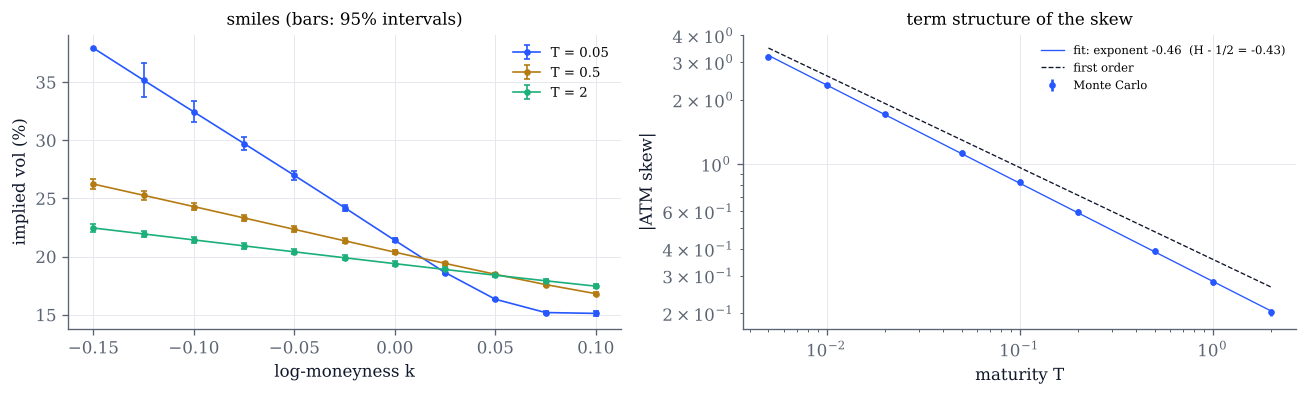

In [11]:
def rbergomi_demo(H=0.07, eta=1.9, rho=-0.9, n_paths_log2=15, seed=1):
    Ts = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0])
    k = np.linspace(-0.15, 0.1, 11)
    o = rbergomi_smiles(k, Ts, H=H, eta=eta, rho=rho, xi=0.235**2, n_steps=128, n_paths=2**n_paths_log2, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    for T, color in zip((0.05, 0.5, 2.0), (COBALT, GOLD, GREEN)):
        j = int(np.argmin(np.abs(Ts - T)))
        ax.errorbar(k, 100 * o["iv"][j], yerr=200 * o["iv_se"][j], fmt="o-", ms=3, lw=1, capsize=2, color=color,
                    label=f"T = {T:g}")
    ax.set(xlabel="log-moneyness k", ylabel="implied vol (%)", title="smiles (bars: 95% intervals)"); ax.legend(fontsize=8)
    A, beta = powerlaw_fit(Ts, o["skew"])
    ax2.errorbar(Ts, np.abs(o["skew"]), yerr=2 * o["skew_se"], fmt="o", color=COBALT, ms=3, label="Monte Carlo")
    TT = np.geomspace(Ts[0], Ts[-1], 100)
    ax2.loglog(TT, A * TT ** beta, color=COBALT, lw=0.8, label=f"fit: exponent {beta:.2f}  (H - 1/2 = {H - 0.5:.2f})")
    ax2.loglog(TT, np.abs(rbergomi_first_order_skew(TT, H, eta, rho)), color=INK, ls="--", lw=0.8, label="first order")
    ax2.set(xlabel="maturity T", ylabel="|ATM skew|", title="term structure of the skew"); ax2.legend(fontsize=7)
    fig.tight_layout(); plt.show()

rbergomi_demo()

In [12]:
# Explore: H sets the exponent of the power law, eta and rho its level. (Each run takes a few seconds.)
interact(rbergomi_demo,
         H=FloatSlider(value=0.07, min=0.03, max=0.45, step=0.02, continuous_update=False, description="H"),
         eta=FloatSlider(value=1.9, min=0.2, max=3.0, step=0.1, continuous_update=False, description="η"),
         rho=FloatSlider(value=-0.9, min=-0.99, max=0.5, step=0.05, continuous_update=False, description="ρ"),
         n_paths_log2=IntSlider(value=15, min=10, max=16, continuous_update=False, description="log2 paths"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 6. Rough Heston: a fractional Riccati equation

The characteristic function of $\log(S_t/S_0)$ is $\exp(\theta\lambda\int_0^th+V_0\int_0^tF(h))$, where $h=I^{H+1/2}[F(h)]$
solves a fractional Riccati equation (fractional Adams method); calls come from Lewis's Fourier formula. At $H=\frac12$
this is the Heston model. Defaults: the parameters of El Euch and Rosenbaum, Section 5.2 ($\lambda=2$, $\rho=-0.5$,
$V_0=0.4$, $\nu=0.05$, $\theta=0.04$).

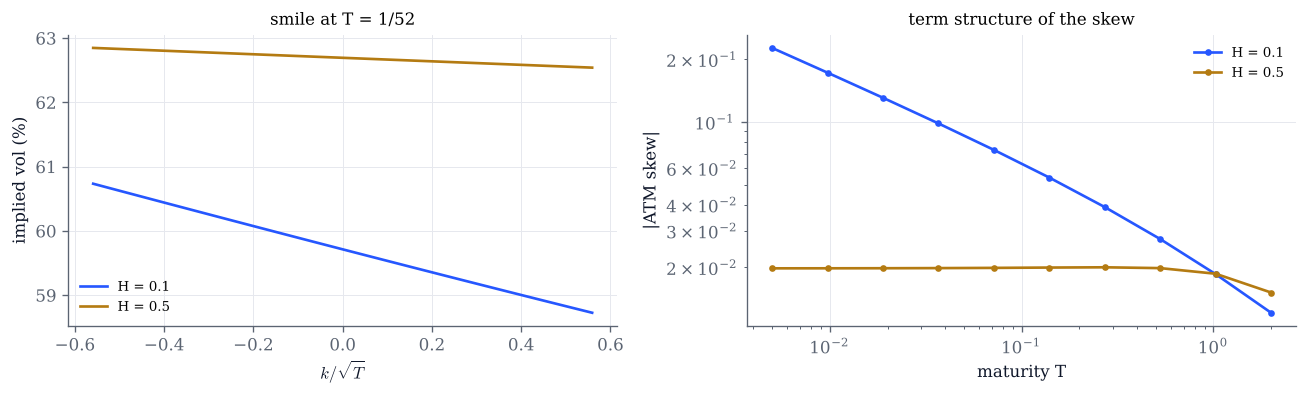

In [13]:
def rough_heston_demo(H=0.1, nu=0.05, rho=-0.5, V0=0.4):
    p = dict(V0=V0, theta=0.04, lam=2.0, nu=nu, rho=rho)
    Ts = np.geomspace(0.005, 2.0, 10)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    T = 1 / 52
    k = np.linspace(-0.25, 0.25, 31) * np.sqrt(T) / np.sqrt(0.2)
    for h, color in ((H, COBALT), (0.5, GOLD)):
        iv, _ = rough_heston_smile(k, T, H=h, n_steps=100, v_eff=V0, **p)
        ax.plot(k / np.sqrt(T), 100 * iv, color=color, label=f"H = {h:g}")
        sk = [rough_heston_smile([0.0], TT, H=h, n_steps=100, v_eff=V0 if TT < 0.2 else None, **p)[1] for TT in Ts]
        ax2.loglog(Ts, np.abs(sk), "o-", ms=3, color=color, label=f"H = {h:g}")
    ax.set(xlabel=r"$k/\sqrt{T}$", ylabel="implied vol (%)", title="smile at T = 1/52"); ax.legend(fontsize=8)
    ax2.set(xlabel="maturity T", ylabel="|ATM skew|", title="term structure of the skew"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()

rough_heston_demo()

In [14]:
interact(rough_heston_demo,
         H=FloatSlider(value=0.1, min=0.02, max=0.5, step=0.02, continuous_update=False, description="H"),
         nu=FloatSlider(value=0.05, min=0.01, max=0.6, step=0.01, continuous_update=False, description="ν"),
         rho=FloatSlider(value=-0.5, min=-0.95, max=0.5, step=0.05, continuous_update=False, description="ρ"),
         V0=FloatSlider(value=0.4, min=0.01, max=0.5, step=0.01, continuous_update=False, description="V0"));

## Things to try

- In Section 1, find the value of $H$ at which the correlations $\rho_H(n)$ change sign. Why do the paths for $H$ close
  to $1$ look almost straight?
- In Section 2, switch the proxy to the 8-hour average: by how much does $\hat H$ rise? Then increase the mean reversion
  $\lambda$ and the maximal lag: when do the log-moment lines stop being straight?
- In Section 5, set $H=0.45$: what happens to the exponent of the skew power law, and to the skew at one week?
  Set $\rho=0$: why does the skew vanish?
- In Section 6, increase $\nu$ (the volatility of volatility) with $H=0.1$ and with $H=0.5$. Which model can produce a
  large skew at one week without a huge skew at two years?